# Лабораторна робота №2

**Токенізатори**

Роман Миджин · 16 жовтня 2026 р.

У цій роботі я реалізував послівну токенізацію, символьні n-грами, BPE та WordPiece.
Потім навчив словники на FLORES і порівняв кількість токенів для трьох мов із GPT.
Усі обчислення виконуються на CPU.

Завдання: [lpnu-llm/lab-tokenizer](https://github.com/lpnu-llm/lab-tokenizer).

Середовище запуску: Python 3.12.7, datasets 4.8.5, tiktoken 0.14.0.


## 1. Токенізація словами

тут текст перетворюється на список слів, чисел і розділових знаків. У `word_tokenize` регулярний вираз знаходить ці частини, а `lower()` переводить їх у нижній регістр.

токен не обов’язково дорівнює слову. Апостроф усередині слова зберігається; великі літери в нашій версії втрачаються.

### Від тексту до входу моделі

Токенізація ділить текст на одиниці, а кодування замінює їх числами. Наприклад, умовний словник може перетворити `кіт спить` на `[7, 12]`. Числа 7 і 12 - це індекси, вони самі по собі не означають схожість слів. Далі embedding-шар дістає для кожного індексу навчений вектор.

У послівного методу зрозумілі токени й короткі послідовності для знайомих слів. Але `кіт`, `кота` і `котові` будуть окремими записами. Якщо залишити всі форми, словник зростає; якщо обмежити його, частішає `<unk>`. Переведення в нижній регістр зменшує кількість варіантів, але стирає різницю між `Роман` і `роман`.


In [1]:
def word_tokenize(text):
    """ділю текст на слова, числа і знаки"""
    import re
    return re.findall(r"[^\W\d_]+(?:['’][^\W\d_]+)*|\d+|[^\w\s]|_", text.lower())

def test_word_tokenize():
    assert word_tokenize("Модель читає текст.") == [
        "модель", "читає", "текст", "."
    ]
    assert word_tokenize("Комп'ютер і пам’ять") == [
        "комп'ютер", "і", "пам’ять"
    ]
    assert word_tokenize("GPT-2: 50 токенів!") == [
        "gpt", "-", "2", ":", "50", "токенів", "!"
    ]
    assert word_tokenize("") == []

if __name__ == "__main__":
    test_word_tokenize()
    print("✓ word_tokenize")

✓ word_tokenize


### Словник і невідомі слова

`build_word_vocab` збирає унікальні токени через `set`, сортує їх через `sorted` і призначає id. `encode_words` замінює токени на ці id; `vocab.get(...)` підставляє `<unk>`, якщо токена немає.

`<pad>` = 0 потрібний для доповнення послідовностей, `<unk>` = 1 позначає невідомий токен. Два різні невідомі слова отримають один id, тому їх не відрізнити. Для embedding-таблиці потрібно приблизно `V × d` параметрів: `V` - розмір словника, `d` - довжина вектора.

In [2]:
def build_word_vocab(texts) -> dict[str, int]:
    "збирає словник зі слів навчального корпусу"
    words = set()
    for text in texts:
        words.update(word_tokenize(text))
    vocab = {"<pad>": 0, "<unk>": 1}
    for word in sorted(words):
        if word not in vocab:
            vocab[word] = len(vocab)
    return vocab

def encode_words(text, vocab):
    "замінює токени на їхні id"
    return [vocab.get(word, vocab["<unk>"]) for word in word_tokenize(text)]

def test_word_vocab():
    vocab = build_word_vocab(["Кіт спить.", "Пес спить."])
    assert vocab["<pad>"] == 0
    assert vocab["<unk>"] == 1
    assert encode_words("Кіт біжить.", vocab) == [vocab["кіт"], 1, vocab["."]]
    assert encode_words("Хом'як біжить.", vocab)[0:2] == [1, 1]

if __name__ == "__main__":
    test_word_vocab()
    print("✓ word vocabulary")

✓ word vocabulary


## 2. Символьні n-грами

`char_ngrams` рухає вікно довжини `n` по слову з маркерами `^` та `$`. Наприклад, `кіт`, `n=3` → `^кі`, `кіт`, `іт$`. Короткі фрагменти частіше збігаються, довгі краще розрізняють слова, але частіше бувають невідомими.

`ngram_overlap` переводить списки у множини й рахує Жаккар: `|A ∩ B| / |A ∪ B|`. Множини вже не зберігають порядок і повторення.

**Шестиграми для короткого слова:** `^кіт$` має 5 символів. При `n=6` поточний код поверне `[]`: вікно не вміщується. Можна додати fallback на коротше слово або padding для строго шестиграм; правило має бути однаковим під час навчання й застосування. У цій лабі такого fallback поки немає. Дві порожні множини в `ngram_overlap` дають 1.0, тому це важливий крайовий випадок.

### Як розмір n змінює розбиття

Для слова довжини `L` після додавання `^` і `$` кількість фрагментів дорівнює `max(0, L + 3 - n)`. Тут `L + 2` - довжина слова з маркерами, а `довжина - n + 1` - кількість положень вікна. Для `кіт` маємо `L=3`: триграми дають 3 фрагменти, шестиграми - 0.

Мале `n` дає короткі фрагменти, які простіше повторно використати в нових словах, але вони слабше розрізняють слова. Велике `n` зберігає більше контексту в одному фрагменті, проте рідкісні й короткі слова покриваються гірше. Fallback може повертати все коротке слово одним фрагментом; тоді його довжина вже не дорівнює `n`. Padding зберігає фіксовану довжину, додаючи спеціальні символи. Це різні правила, їх не слід змішувати між навчанням і застосуванням.

N-грами тут перекриваються: літера може входити одразу в кілька фрагментів. Тому це інше представлення, ніж послідовне неперекривне розбиття BPE або WordPiece. Жаккар вимірює спільність наборів фрагментів: 0 означає відсутність спільних елементів, 1 - однакові множини. Він не перевіряє однаковість початкових слів.


In [3]:
def char_ngrams(word, n=3):
    "ділить слово на фрагменти по n символів"
    if n <= 0:
        raise ValueError("n має бути більше нуля")
    if not word:
        return []
    marked = "^" + word + "$"
    return [marked[i:i + n] for i in range(len(marked) - n + 1)]

def ngram_overlap(word_a, word_b, n=3):
    "порівнює множини n-грам"
    a = set(char_ngrams(word_a, n))
    b = set(char_ngrams(word_b, n))
    if not a and not b:
        return 1.0
    return len(a & b) / len(a | b)

def test_ngrams():
    assert char_ngrams("кіт", 3) == ["^кі", "кіт", "іт$"]
    assert char_ngrams("кіт", 2) == ["^к", "кі", "іт", "т$"]
    assert char_ngrams("", 3) == []
    assert ngram_overlap("токенізатор", "токенізація", 3) > 0.4
    assert ngram_overlap("кіт", "трактор", 3) == 0.0

    try:
        char_ngrams("слово", 0)
    except ValueError:
        pass
    else:
        raise AssertionError("n має бути додатним")

if __name__ == "__main__":
    test_ngrams()
    print("✓ character n-grams")

✓ character n-grams


### Словник n-грам

`build_ngram_vocab` збирає всі відомі n-грами корпусу й призначає їм id. `encode_ngrams` створює фрагменти нового тексту й шукає кожен у цьому словнику.

правило розбиття задається числом `n`, а навчання тут - збирання словника відомих фрагментів. Новий алфавіт або нова комбінація символів усе одно можуть дати `<unk>`.

In [4]:
def build_ngram_vocab(texts, n=3):
    "збирає відомі n-грами навчального корпусу"
    grams = set()
    for text in texts:
        for word in word_tokenize(text):
            grams.update(char_ngrams(word, n))
    vocab = {"<pad>": 0, "<unk>": 1}
    for gram in sorted(grams):
        vocab[gram] = len(vocab)
    return vocab

def encode_ngrams(text, vocab, n=3):
    "замінює n-грами тексту на id зі словника"
    return [vocab.get(gram, vocab["<unk>"])
            for word in word_tokenize(text)
            for gram in char_ngrams(word, n)]

def test_ngram_vocab():
    vocab = build_ngram_vocab(["кіт"], 3)
    assert len(encode_ngrams("кіт", vocab)) == 3
    assert 1 not in encode_ngrams("кіт", vocab)
    assert 1 in encode_ngrams("cat", vocab)
    assert vocab["<pad>"] == 0 and vocab["<unk>"] == 1

if __name__ == "__main__":
    test_ngram_vocab()
    print("✓ n-gram vocabulary")

✓ n-gram vocabulary


## 3. BPE - Byte Pair Encoding

починаю із символів і маркера кінця слова `</w>`. Потім знаходжу найчастішу сусідню пару, зливаю її й повторюю процес. Часті частини слів поступово стають одним токеном.

`word_frequencies` рахує частоти слів без чисел і пунктуації; `most_frequent_pair` рахує сусідні пари з урахуванням цих частот; `merge_pair` виконує саме злиття. Це навчання за частотами, без градієнтів.

In [5]:
def word_frequencies(texts):
    "рахує слова без чисел і пунктуації"
    from collections import Counter
    counts = Counter()
    for text in texts:
        for token in word_tokenize(text):
            if token[0].isalpha():
                counts[token] += 1
    return dict(counts)

def most_frequent_pair(vocabulary):
    "шукає найчастішу пару, враховуючи повторення слів"
    from collections import Counter
    pairs = Counter()
    for symbols, count in vocabulary.items():
        for pair in zip(symbols, symbols[1:]):
            pairs[pair] += count
    if not pairs:
        return None
    return min(pairs, key=lambda pair: (-pairs[pair], pair))

def merge_pair(symbols, pair):
    "зливає сусідні елементи вибраної пари"
    result = []
    i = 0
    while i < len(symbols):
        if i + 1 < len(symbols) and (symbols[i], symbols[i + 1]) == pair:
            result.append(symbols[i] + symbols[i + 1])
            i += 2
        else:
            result.append(symbols[i])
            i += 1
    return tuple(result)

### BPE: оновлення частот

`_training_counts` зберігає слова, їхні частоти, частоти пар і список слів для кожної пари. `_merge_training_pair` оновлює тільки ті слова, де є вибрана пара.

ці дві допоміжні функції прискорюють перерахунок. Правило алгоритму лишається тим самим - наступною обирається найчастіша пара.

In [6]:
def _training_counts(vocabulary):
    "зберігає частоти і список слів, у яких є кожна пара"
    from collections import Counter, defaultdict
    words = list(vocabulary)
    counts = list(vocabulary.values())
    pair_counts = Counter()
    pair_words = defaultdict(set)
    symbol_counts = Counter()
    for index, symbols in enumerate(words):
        count = counts[index]
        for symbol in symbols:
            symbol_counts[symbol] += count
        for pair in zip(symbols, symbols[1:]):
            pair_counts[pair] += count
            pair_words[pair].add(index)
    return words, counts, pair_counts, pair_words, symbol_counts

def _merge_training_pair(state, pair, merge):
    "оновлює частоти тільки у словах із вибраною парою"
    from collections import Counter
    words, counts, pair_counts, pair_words, symbol_counts = state
    for index in list(pair_words[pair]):
        old = words[index]
        new = merge(old, pair)
        count = counts[index]
        for symbol, amount in Counter(old).items():
            symbol_counts[symbol] -= amount * count
        for symbol, amount in Counter(new).items():
            symbol_counts[symbol] += amount * count
        for old_pair, amount in Counter(zip(old, old[1:])).items():
            pair_counts[old_pair] -= amount * count
            pair_words[old_pair].discard(index)
            if pair_counts[old_pair] == 0:
                del pair_counts[old_pair]
        for new_pair, amount in Counter(zip(new, new[1:])).items():
            pair_counts[new_pair] += amount * count
            pair_words[new_pair].add(index)
        words[index] = new

### BPE: навчання й застосування

`train_bpe` створює початкові послідовності символів, вибирає пари й записує їх у `merges`. Ключ `(-частота, пара)` у `min` дає найбільшу частоту, а при рівності - першу пару за абетковим порядком.

`apply_bpe` застосовує записані злиття до нового слова в тому самому порядку. `i += 2` у `merge_pair` означає, що злиті входження не перекриваються. `</w>` може залишитися окремим токеном або приєднатися до фрагмента.

### Приклад одного злиття

Нехай у навчанні є `кіт` двічі та `кит` один раз. Спочатку це `[к, і, т, </w>]` і `[к, и, т, </w>]`. Пара `(т, </w>)` зустрічається 3 рази з урахуванням частот, а `(к, і)` - 2 рази. Після першого злиття кінцівка `т</w>` стає одним токеном у всіх відповідних словах. Далі частоти рахуються вже для змінених послідовностей.

При застосуванні нового навчання немає: слово розбивається на символи, після чого до нього застосовуються збережені правила. Порядок `merges` важливий, бо раннє злиття може створити частину для наступного. У нашій реалізації BPE працює всередині слів і не зливає частини через пробіли.


In [7]:
def train_bpe(texts, num_merges):
    "навчає послідовність злиттів BPE"
    if num_merges < 0:
        raise ValueError("кількість злиттів не може бути від’ємною")
    vocabulary = {}
    for word, count in word_frequencies(texts).items():
        vocabulary[tuple(word) + ("</w>",)] = count
    state = _training_counts(vocabulary)
    pair_counts = state[2]
    merges = []
    for _ in range(num_merges):
        if not pair_counts:
            break
        pair = min(pair_counts, key=lambda p: (-pair_counts[p], p))
        _merge_training_pair(state, pair, merge_pair)
        merges.append(pair)
    return merges

def apply_bpe(word, merges):
    "застосовує злиття в тому порядку, як їх вивчили"
    if not word:
        return []
    symbols = tuple(word) + ("</w>",)
    for pair in merges:
        symbols = merge_pair(symbols, pair)
    return list(symbols)

def test_bpe():
    vocabulary = {
        ("м", "а", "м", "а", "</w>"): 2,
        ("м", "а", "л", "а", "</w>"): 1,
    }
    assert most_frequent_pair(vocabulary) == ("м", "а")
    assert merge_pair(("м", "а", "м", "а", "</w>"), ("м", "а")) == (
        "ма", "ма", "</w>"
    )

    merges = train_bpe(["мама мама мала тон"], 3)
    assert merges[0] == ("м", "а")
    assert apply_bpe("мама", merges) == ["мама</w>"]

    unseen = apply_bpe("мамонт", merges)
    assert "<unk>" not in unseen
    assert "".join(unseen).replace("</w>", "") == "мамонт"

if __name__ == "__main__":
    test_bpe()
    print("✓ BPE")

✓ BPE


### Довжина BPE-послідовностей

`average_bpe_length` множить кількість токенів слова на частоту цього слова, складає результат і ділить на загальну кількість слів. Часті слова мають більшу вагу.

більше злиттів зазвичай дає коротші послідовності ціною більшого словника. Окремий test-корпус потрібний, щоб перевірити нові тексти. Наш символьний BPE може повернути новий символ поза навчальним словником; byte-level BPE використовує початкові 256 байтів і може представити будь-який UTF-8 текст.
**Відмінність від таблиці fertility:** ця функція рахує тільки слова з `word_frequencies`, без чисел і пунктуації. У великому порівнянні токенізується весь текст.


In [8]:
def average_bpe_length(texts, merges):
    "рахує середню довжину слова в BPE-токенах"
    frequencies = word_frequencies(texts)
    total_words = sum(frequencies.values())
    if total_words == 0:
        raise ValueError("у корпусі немає слів")
    total_tokens = sum(len(apply_bpe(word, merges)) * count
                       for word, count in frequencies.items())
    return total_tokens / total_words

def test_average_bpe_length():
    corpus = [
        "токен токени токенізація",
        "токенізатор токенізує текст",
    ]
    merges = train_bpe(corpus, 20)
    before = average_bpe_length(corpus, [])
    after = average_bpe_length(corpus, merges)
    assert after < before
    assert before > 1

if __name__ == "__main__":
    test_average_bpe_length()
    print("✓ BPE reduces average sequence length")

✓ BPE reduces average sequence length


## 4. WordPiece

тут `##` позначає продовження слова: `токен`, `##ізація`. `wordpiece_symbols` додає цей префікс до всіх символів, крім першого; `merge_wordpiece_pair` прибирає зайвий внутрішній `##` під час злиття.

`wordpiece_pair_scores` рахує `score(a,b) = freq(a,b) / (freq(a) × freq(b))`. Чисельник - частота пари, знаменник - добуток частот її частин. **На відміну від BPE, найчастіша пара не обов’язково має найвищий score.** Це навчальна схема WordPiece з умови.

In [9]:
def wordpiece_symbols(word):
    "додає ## до символів, які продовжують слово"
    if not word:
        return ()
    return (word[0],) + tuple("##" + char for char in word[1:])

def wordpiece_pair_scores(vocabulary):
    "рахує оцінку пари за частотами її частин"
    from collections import Counter
    symbols_count = Counter()
    pairs_count = Counter()
    for symbols, count in vocabulary.items():
        for symbol in symbols:
            symbols_count[symbol] += count
        for pair in zip(symbols, symbols[1:]):
            pairs_count[pair] += count
    return {pair: count / (symbols_count[pair[0]] * symbols_count[pair[1]])
            for pair, count in pairs_count.items()}

def merge_wordpiece_pair(symbols, pair):
    "зливає пару і залишає один префікс продовження"
    result = []
    i = 0
    while i < len(symbols):
        if i + 1 < len(symbols) and (symbols[i], symbols[i + 1]) == pair:
            result.append(symbols[i] + symbols[i + 1].removeprefix("##"))
            i += 2
        else:
            result.append(symbols[i])
            i += 1
    return tuple(result)

### WordPiece: навчання словника

`train_wordpiece` починає зі стартових символів, варіантів із `##` та `[UNK]`. Далі додає злиття з найвищим score до потрібного розміру словника.

**Чим це відрізняється від BPE:** вибираємо найбільш пов’язану за цією формулою пару, а не просто найчастішу. Наприклад, рідкісна пара з частотами 1 / (1 × 1) має score 1 і може випередити часту пару 100 / (1000 × 1000).

### Що означає score

Якщо `freq(a,b)=20`, `freq(a)=100`, `freq(b)=50`, то `score=20/(100×50)=0.004`. Для іншої пари з частотами `2`, `2`, `2` отримаємо `2/(2×2)=0.5`. BPE обрав би першу пару за частотою 20, а наша схема WordPiece - другу за score 0.5.

Такий score підсилює пару, частини якої часто трапляються саме разом порівняно з їхніми окремими частотами. Це показник для вибору злиття, а не ймовірність слова чи оцінка його змісту. Рідкісна пара може мати великий score й водночас скоротити зовсім небагато токенів корпусу.


In [10]:
def train_wordpiece(texts, vocab_size):
    "навчає словник WordPiece"
    if vocab_size <= 0:
        raise ValueError("розмір словника має бути більше нуля")
    vocabulary = {wordpiece_symbols(word): count
                  for word, count in word_frequencies(texts).items()}
    vocab = {"[UNK]"}
    for symbols in vocabulary:
        vocab.update(symbols)
    if len(vocab) > vocab_size:
        raise ValueError("словник менший за початковий алфавіт")
    state = _training_counts(vocabulary)
    pair_counts = state[2]
    symbol_counts = state[4]
    while len(vocab) < vocab_size:
        if not pair_counts:
            break
        pair = min(pair_counts, key=lambda p: (
            -pair_counts[p] / (symbol_counts[p[0]] * symbol_counts[p[1]]), p
        ))
        merged_token = pair[0] + pair[1].removeprefix("##")
        _merge_training_pair(state, pair, merge_wordpiece_pair)
        vocab.add(merged_token)
    return vocab

### WordPiece: як розбивається нове слово

`start` - початок ще не обробленої частини, а `end` рухається від кінця слова назад. Перший знайдений фрагмент - найдовший; для позицій усередині слова додається `##`.

**Нюанс `[UNK]`:** якщо хоч одна частина не знаходиться, функція повертає `[UNK]` для всього слова, навіть якщо попередні частини вже знайшла. Порожнє слово повертає `[]`. Це greedy longest-match, а не застосування історії злиттів BPE.

Наприклад, для словника з `токен` і `##ізація` слово `токенізація` можна подати двома частинами. Початковий токен шукається без `##`, продовження - з ним. Якщо `##ізація` та інші потрібні продовження відсутні, результатом буде один `[UNK]` для всього слова.

Greedy означає, що на кожному кроці береться найдовший доступний фрагмент. Повернення до коротшого вже вибраного початку в нас немає. Тому навіть за наявності іншого можливого повного розбиття невдале greedy-рішення може завершитися `[UNK]`. BPE натомість відтворює порядок злиттів; WordPiece для кодування використовує готовий словник, а історія його побудови вже не потрібна.


In [11]:
def apply_wordpiece(word, vocab, unk_token="[UNK]"):
    "на кожній позиції бере найдовший відомий фрагмент"
    pieces = []
    start = 0
    while start < len(word):
        found = None
        for end in range(len(word), start, -1):
            piece = word[start:end]
            if start > 0:
                piece = "##" + piece
            if piece in vocab:
                found = piece
                start = end
                break
        if found is None:
            return [unk_token]
        pieces.append(found)
    return pieces

def test_wordpiece():
    weighted_vocab = {
        ("а", "##б"): 2,
        ("а", "##в"): 1,
        ("г", "##в"): 2,
    }
    scores = wordpiece_pair_scores(weighted_vocab)
    assert scores[("а", "##б")] > scores[("а", "##в")]
    assert merge_wordpiece_pair(("м", "##а", "##м", "##а"), ("м", "##а")) == (
        "ма", "##м", "##а"
    )

    vocab = train_wordpiece(["мама мама мала тон"], 30)
    assert "[UNK]" in vocab
    assert apply_wordpiece("мама", vocab) == ["мама"]

    bert_vocab = {"[UNK]", "ток", "токен", "##ен", "##ізація"}
    assert apply_wordpiece("токенізація", bert_vocab) == ["токен", "##ізація"]
    assert apply_wordpiece("токенx", bert_vocab) == ["[UNK]"]
    assert apply_wordpiece("", bert_vocab) == []

    try:
        train_wordpiece(["текст"], 0)
    except ValueError:
        pass
    else:
        raise AssertionError("vocab_size має бути додатним")

if __name__ == "__main__":
    test_wordpiece()
    print("✓ WordPiece")

✓ WordPiece


## 5. FLORES і порівняння з GPT

`load_flores_dev` завантажує по 997 речень англійською, українською та грузинською. `train_texts` об’єднує їх в один навчальний список із 2991 речення.

**Навіщо порівну:** одна мова не отримує перевагу через більшу кількість прикладів. Речення паралельні, тому зміст відповідних рядків однаковий. Але кількість слів і символів може відрізнятися, а 997 речень не представляють усю мову.

Джерело: [tomasmajercik/flores-parquet](https://huggingface.co/datasets/tomasmajercik/flores-parquet), `validation` (FLORES dev), revision `dde46bb7d02cc6a45e9568d2ddb4fa6585412434`. За умовою власні BPE і WordPiece навчаються тільки на словах, без чисел і пунктуації.

In [12]:
from datasets import load_dataset

FLORES_LANGUAGES = {
    "English": "eng_Latn",
    "Українська": "ukr_Cyrl",
    "ქართული": "kat_Geor",
}

def load_flores_dev():
    "Завантажує по 997 речень FLORES для кожної вибраної мови."
    corpora = {}
    for language, config in FLORES_LANGUAGES.items():
        dataset = load_dataset(
            "tomasmajercik/flores-parquet",
            config,
            split="validation",
            revision="dde46bb7d02cc6a45e9568d2ddb4fa6585412434",
        )
        corpora[language] = list(dataset["sentence"])
    return corpora

if __name__ == "__main__":
    flores = load_flores_dev()

    assert all(len(texts) == 997 for texts in flores.values())
    train_texts = [
        text
        for language_texts in flores.values()
        for text in language_texts
    ]

    print({language: len(texts) for language, texts in flores.items()})
    print("Усього навчальних рядків:", len(train_texts))

{'English': 997, 'Українська': 997, 'ქართული': 997}
Усього навчальних рядків: 2991


### Один зміст трьома мовами

індекс `example_index` вибирає відповідні переклади одного речення. Так можна порівнювати токенізацію схожого змісту, а не різних тем.

In [13]:
if __name__ == "__main__":
    example_index = 0
    for language, texts in flores.items():
        print(f"{language}: {texts[example_index]}\n")

English: On Monday, scientists from the Stanford University School of Medicine announced the invention of a new diagnostic tool that can sort cells by type: a tiny printable chip that can be manufactured using standard inkjet printers for possibly about one U.S. cent each.

Українська: У понеділок, науковці зі Школи медицини Стенфордського університету оголосили про винайдення нового діагностичного інструменту, що може сортувати клітини за їх видами: це малесенький друкований чіп, який можна виготовити за допомогою стандартних променевих принтерів десь по одному центу США за штуку.

ქართული: ორშაბათს, სტენფორდის უნივერსიტეტის სამედიცინო კათედრის მეცნიერებმა გააკეთეს განცხადება ახალი დიაგნოსტიკური ხელსაწყოს გამოგონების შესახებ, რომელსაც უჯრედის ტიპებად დაყოფა შეუძლია: წვრილი, დასაბეჭდი ჩიპი, რომლის წარმოებაც შესაძლებელია ჩვეულებრივი ჭავლური პრინტერის საშუალებით. ერთი ცალის სავარაუდო ღირებულება აშშ ცენტს შეადგენს.



### Навчання словників 500, 1000 і 2000

`VOCAB_SIZES` задає три цільові розміри. Для BPE `bpe_num_merges` віднімає початковий алфавіт і `</w>`: кожне нове злиття додає токен. WordPiece також враховує початкові символи, продовження з `##` та `[UNK]`.

`apply_bpe_to_text` і `apply_wordpiece_to_text` застосовують алгоритм до всіх токенів речення. **Більший словник** потребує більше навчальних кроків і пам’яті, але може дати коротший вхід моделі. Токени не зобов’язані розподілятися порівну між мовами: частоти фрагментів різні.

In [14]:
VOCAB_SIZES = (500, 1000, 2000)

def bpe_num_merges(texts, vocab_size):
    "Обчислює кількість BPE-merges для бажаного розміру словника."
    frequencies = word_frequencies(texts)
    characters = {
        character
        for word in frequencies
        for character in word
    }
    initial_vocab_size = len(characters) + 1
    if vocab_size < initial_vocab_size:
        raise ValueError("vocab_size менший за початковий алфавіт")
    return vocab_size - initial_vocab_size

def apply_bpe_to_text(text, merges):
    "Застосовує створений раніше BPE до всіх токенів тексту."
    return [
        piece
        for token in word_tokenize(text)
        for piece in apply_bpe(token, merges)
    ]

def apply_wordpiece_to_text(text, vocab):
    "Застосовує створений раніше WordPiece до всіх токенів тексту."
    return [
        piece
        for token in word_tokenize(text)
        for piece in apply_wordpiece(token, vocab)
    ]

if __name__ == "__main__":
    bpe_models = {}
    wordpiece_models = {}

    for vocab_size in VOCAB_SIZES:
        print("Навчаю словники:", vocab_size, flush=True)
        bpe_models[vocab_size] = train_bpe(
            train_texts,
            bpe_num_merges(train_texts, vocab_size),
        )
        wordpiece_models[vocab_size] = train_wordpiece(
            train_texts,
            vocab_size,
        )

    print("Навчено BPE і WordPiece для:", VOCAB_SIZES)

Навчаю словники: 500


Навчаю словники: 1000


Навчаю словники: 2000


Навчено BPE і WordPiece для: (500, 1000, 2000)


### Готові GPT-токенізатори

`tiktoken.encoding_for_model(...)` вибирає готовий encoding; `encoding.encode(text)` повертає список id. Це локальна токенізація: модель не генерує відповіді, API-ключ не потрібний. Перший запуск завантажує дані encoding-ів.

**Відповідності:** GPT-2 → `gpt2`; GPT-3.5 і GPT-4 → `cl100k_base`; GPT-5 → `o200k_base`. Саме тому GPT-3.5 і GPT-4 у таблиці однакові.

In [15]:
import tiktoken

if __name__ == "__main__":
    gpt_encodings = {
        "GPT-2": tiktoken.encoding_for_model("gpt-2"),
        "GPT-3.5": tiktoken.encoding_for_model("gpt-3.5-turbo"),
        "GPT-4": tiktoken.encoding_for_model("gpt-4"),
        "GPT-5": tiktoken.encoding_for_model("gpt-5"),
    }

    for name, encoding in gpt_encodings.items():
        print(f"{name:7} -> {encoding.name:12} ({encoding.n_vocab} tokens)")

GPT-2   -> gpt2         (50257 tokens)
GPT-3.5 -> cl100k_base  (100277 tokens)
GPT-4   -> cl100k_base  (100277 tokens)
GPT-5   -> o200k_base   (200019 tokens)


### Fertility

`fertility = загальна кількість токенів / загальна кількість слів`. У `fertility` чисельник рахується через `len(tokenize(text))`, знаменник - через `len(text.split())`. Ділимо суми всього корпусу, а не усереднюємо значення речень.

`fertility_table` повторює підрахунок для кожної мови й токенізатора. `cached_subword_tokenizer` запам’ятовує розбиття вже оброблених слів: це прискорення без зміни токенів.

fertility 3 означає в середньому три токени на слово. Нижча fertility - коротша послідовність, але `[UNK]` теж займає одну позицію й може приховувати втрату цілого слова. Для порожнього корпусу видаю помилку, щоб не ділити на нуль.

### Як читати значення

Якщо 100 слів перетворилися на 250 токенів, fertility дорівнює `250/100=2.5`. У нашому знаменнику слово - це частина тексту між пробілами, тому `кіт,` є одним словом, хоча токенізатор може окремо видати `кіт` і кому. Через це результат залежить і від пунктуації, і від визначення слова.

Ділення сум дає кожному слову однакову вагу. Просте середнє fertility речень дало б однакову вагу короткому й довгому реченням, тому результат міг би відрізнятися.

Низька fertility за доброго покриття означає менше позицій для моделі: у фіксоване контекстне вікно вміщується більше тексту. Для стандартної повної self-attention її матриця має розмір `T×T`, де `T` - кількість токенів, тому довжина впливає на витрати. Але час роботи всієї моделі не визначається лише fertility. А якщо невідоме слово замінилося одним `[UNK]`, коротка послідовність отримана через втрату інформації.


In [16]:
def fertility_table(tokenizers, corpora):
    "збирає fertility для кожного токенізатора і мови"
    results = {}
    for name, tokenize in tokenizers.items():
        results[name] = {}
        for language, texts in corpora.items():
            results[name][language] = fertility(tokenize, texts)
    return results

def cached_subword_tokenizer(tokenize_word):
    "повторно використовує готове розбиття знайомих слів"
    from functools import lru_cache
    cached_word = lru_cache(maxsize=50000)(tokenize_word)

    def tokenize(text):
        return [piece for word in word_tokenize(text)
                for piece in cached_word(word)]
    return tokenize

def fertility(tokenize, texts):
    "ділить загальну кількість токенів на кількість слів"
    total_tokens = 0
    total_words = 0
    for text in texts:
        total_tokens += len(tokenize(text))
        total_words += len(text.split())
    if total_words == 0:
        raise ValueError("у корпусі немає слів")
    return total_tokens / total_words

def test_fertility():
    assert fertility(list, ["aa b", "ccc"]) == 7 / 3

    try:
        fertility(list, ["", "   "])
    except ValueError:
        pass
    else:
        raise AssertionError("Корпус без слів має давати ValueError")

if __name__ == "__main__":
    test_fertility()
    print("✓ fertility")

✓ fertility


### Таблиця для десяти токенізаторів

`tokenizers_to_compare` містить функції токенізації, а `results` - fertility для кожної мови. У `lambda ... merges=merges` і `vocab=vocab` поточна модель фіксується в аргументі за замовчуванням; без цього всі функції циклу могли б використати останній словник.

**Чому BPE знижує fertility сильніше:** він зливає найчастіші пари й скорочує багато повторень. WordPiece-score може вибирати рідкісні фрагменти, що мало впливають на весь корпус. Для української BPE: 4.323 → 3.185, WordPiece: 5.945 → 5.412 при збільшенні словника 500 → 2000. Це властивість нашого досліду, а не загальне правило для WordPiece.

**Обмеження:** власні моделі перевірені на тому самому dev, де навчалися. Це train fertility, а не оцінка узагальнення. GPT має інші дані, значно більші словники та зберігає регістр, тому умови відрізняються.

In [17]:
if __name__ == "__main__":
    tokenizers_to_compare = {}

    for vocab_size, merges in bpe_models.items():
        tokenizers_to_compare[f"BPE-{vocab_size}"] = cached_subword_tokenizer(
            lambda word, merges=merges: apply_bpe(word, merges)
        )

    for vocab_size, vocab in wordpiece_models.items():
        tokenizers_to_compare[f"WordPiece-{vocab_size}"] = cached_subword_tokenizer(
            lambda word, vocab=vocab: apply_wordpiece(word, vocab)
        )

    for name, encoding in gpt_encodings.items():
        tokenizers_to_compare[name] = encoding.encode

    results = fertility_table(tokenizers_to_compare, flores)

    header = f"{'tokenizer':<24}" + "".join(
        f"{language:>14}" for language in flores
    )
    print(header)
    print("-" * len(header))
    for tokenizer_name, language_values in results.items():
        row = f"{tokenizer_name:<24}" + "".join(
            f"{language_values[language]:14.3f}" for language in flores
        )
        print(row)

tokenizer                      English    Українська       ქართული
------------------------------------------------------------------
BPE-500                          3.387         4.323         4.928
BPE-1000                         2.886         3.668         4.208
BPE-2000                         2.469         3.185         3.565
WordPiece-500                    4.827         5.945         7.307
WordPiece-1000                   4.784         5.810         7.169
WordPiece-2000                   4.774         5.412         7.160
GPT-2                            1.228         8.024        21.545
GPT-3.5                          1.231         4.202        15.345
GPT-4                            1.231         4.202        15.345
GPT-5                            1.219         2.442         2.780


### Змішані й складні речення

`compare_mixed_cases` нумерує речення й рахує `len(tokenize(text))` для кожного варіанта. Номери стовпців відповідають реченням вище таблиці.

**Що тут перевіряю:** перемикання мов, числа, email, URL та emoji. Середнє значення по корпусу може приховувати невдалі розбиття, тому нижче є й самі токени.

In [18]:
MIXED_CASES = [
    "Я навчаю tokenizer на FLORES dataset.",
    "The model розуміє ქართულ ენას?",
    "Київ -> Tbilisi -> თბილისი -> London 🌍",
    "Замовлення №2026-09-24 коштує $19.99.",
    "support@example.com або https://example.com/допомога",
    "я дуже втомився від курсу основи Large Language Models"
]

def compare_mixed_cases(texts, tokenizers):
    "показує кількість токенів у змішаних реченнях"
    for index, text in enumerate(texts, 1):
        print(f"{index}. {text}")
    print()
    print(f"{'tokenizer':<18}" + "".join(f"{i:>7}" for i in range(1, len(texts) + 1)))
    for name, tokenize in tokenizers.items():
        counts = [len(tokenize(text)) for text in texts]
        print(f"{name:<18}" + "".join(f"{count:>7}" for count in counts))


if __name__ == "__main__":
    compare_mixed_cases(MIXED_CASES, tokenizers_to_compare)

1. Я навчаю tokenizer на FLORES dataset.
2. The model розуміє ქართულ ენას?
3. Київ -> Tbilisi -> თბილისი -> London 🌍
4. Замовлення №2026-09-24 коштує $19.99.
5. support@example.com або https://example.com/допомога
6. я дуже втомився від курсу основи Large Language Models

tokenizer               1      2      3      4      5      6
BPE-500                24     18     33     38     42     37
BPE-1000               23     16     31     38     39     28
BPE-2000               19     15     29     37     36     20
WordPiece-500          32     25     31     27     47     46
WordPiece-1000         32     25     31     27     46     46
WordPiece-2000         32     25     31     27     46     46
GPT-2                  21     43     37     34     24     37
GPT-3.5                13     31     30     22     16     20
GPT-4                  13     31     30     22     16     20
GPT-5                  10     10     14     18     13     14


## 6. Послівний словник і триграми на FLORES

на тих самих 2991 реченні будую словник слів і словник триграм. `baselines` зберігає функції, які повертають id; `ids.count(1)` рахує невідомі елементи, бо `<unk>` має id 1.

**Чому тут нуль невідомих:** це той самий навчальний корпус. На нових прикладах OOV уже з’являється. Відсоток UNK для слів рахується серед словесних токенів, а для триграм - серед n-грам, тому ці відсотки мають різні одиниці підрахунку.

In [19]:
if __name__ == "__main__":
    word_vocab = build_word_vocab(train_texts)
    trigram_vocab = build_ngram_vocab(train_texts, 3)
    baselines = {
        "Words": lambda text: encode_words(text, word_vocab),
        "Trigrams": lambda text: encode_ngrams(text, trigram_vocab, 3),
    }
    print("Словник слів:", len(word_vocab))
    print("Словник триграм:", len(trigram_vocab))
    print(f"{'tokenizer':<12} {'language':<14} {'fertility':>10} {'UNK, %':>9}")
    for name, tokenize_text in baselines.items():
        for language, texts in flores.items():
            ids = [token for text in texts for token in tokenize_text(text)]
            unknown_rate = 100 * ids.count(1) / len(ids) if ids else 0
            print(f"{name:<12} {language:<14} {fertility(tokenize_text, texts):10.3f} {unknown_rate:9.2f}")

Словник слів: 21352
Словник триграм: 15649
tokenizer    language        fertility    UNK, %
Words        English             1.146      0.00
Words        Українська          1.207      0.00
Words        ქართული             1.228      0.00
Trigrams     English             5.022      0.00


Trigrams     Українська          6.062      0.00
Trigrams     ქართული             7.416      0.00


## 7. Розміри словників і невідомі токени

для BPE збираю початковий алфавіт і результати злиттів у `set`, щоб перевірити фактичний розмір словника. Для WordPiece порівнюю результат кожного вхідного токена з `[UNK]`.

**Нюанс:** 13.22% / 18.24% / 19.01% - це частка одиниць `word_tokenize`, які стали `[UNK]`, для англійської / української / грузинської. Це не відсоток усіх вихідних підслів. Тут є числа й пунктуація, яких за умовою не було в навчанні, тому збільшення словника букв саме по собі їх не додає.

In [20]:
if __name__ == "__main__":
    alphabet = set("".join(word_frequencies(train_texts))) | {"</w>"}
    for size, merges in bpe_models.items():
        learned = alphabet | {a + b for a, b in merges}
        print(f"BPE-{size}: {len(learned)} токенів, {len(merges)} злиттів")
    for size, vocab in wordpiece_models.items():
        print(f"WordPiece-{size}: {len(vocab)} токенів")
    print()
    for language, texts in flores.items():
        words = [word for text in texts for word in word_tokenize(text)]
        rates = []
        for size, vocab in wordpiece_models.items():
            unknown = sum(apply_wordpiece(word, vocab) == ["[UNK]"] for word in words)
            rates.append(f"WP-{size}: {100 * unknown / len(words):.2f}%")
        print(language, "; ".join(rates))

BPE-500: 500 токенів, 396 злиттів
BPE-1000: 1000 токенів, 896 злиттів
BPE-2000: 2000 токенів, 1896 злиттів
WordPiece-500: 500 токенів
WordPiece-1000: 1000 токенів
WordPiece-2000: 2000 токенів



English WP-500: 13.22%; WP-1000: 13.22%; WP-2000: 13.22%


Українська WP-500: 18.24%; WP-1000: 18.24%; WP-2000: 18.24%


ქართული WP-500: 19.01%; WP-1000: 19.01%; WP-2000: 19.01%


## 8. Порівняння fertility на графіку

`values` збирає ту саму таблицю `results` у матрицю: рядки - токенізатори, стовпці - мови. Колір і підписи показують кількість токенів на слово.

**Що говорять числа:** GPT-2 має 1.228 для англійської, 8.024 для української та 21.545 для грузинської. GPT-5 у цьому досліді має найнижчі значення: 1.219 / 2.442 / 2.780. Це порівняння токенізаторів, а не якості відповідей моделей.

**Чому українська дорожча для GPT-2:** його словник краще покриває англомовні фрагменти; українська має багатшу словозміну (`студент`, `студента`, `студентами`); кирилична літера зазвичай займає 2 байти UTF-8 проти 1 для ASCII. Без потрібних байтових злиттів слово сильніше дробиться. Роди й відмінки - лише частина пояснення. Два байти не означають автоматично два токени.

### Чому результати мов відрізняються

Українська має багато форм одного слова: число, відмінок, рід та інші граматичні зміни створюють різні закінчення й комбінації. Англійська також має словозміну, але її система відмінкових форм значно менша. Це ускладнює покриття всіх українських форм цілими токенами, однак вдало навчений підслівний словник може повторно використовувати основи та закінчення.

Окремий чинник - покриття мови конкретним словником. GPT-2 набагато краще представляє англійські фрагменти. Кирилиця й грузинське письмо кодуються кількома байтами UTF-8; якщо потрібних злиттів бракує, байтове представлення дробиться сильніше. Тож велику різницю не можна пояснювати лише відмінками або лише кількістю байтів.

Однакова кількість паралельних речень контролює обсяг прикладів і їхній зміст. Вона не вирівнює довжину перекладів, кількість слів, частоти літер або число різних форм. Наш спільний словник усе одно розподіляє місця відповідно до правил алгоритму та частот корпусу.


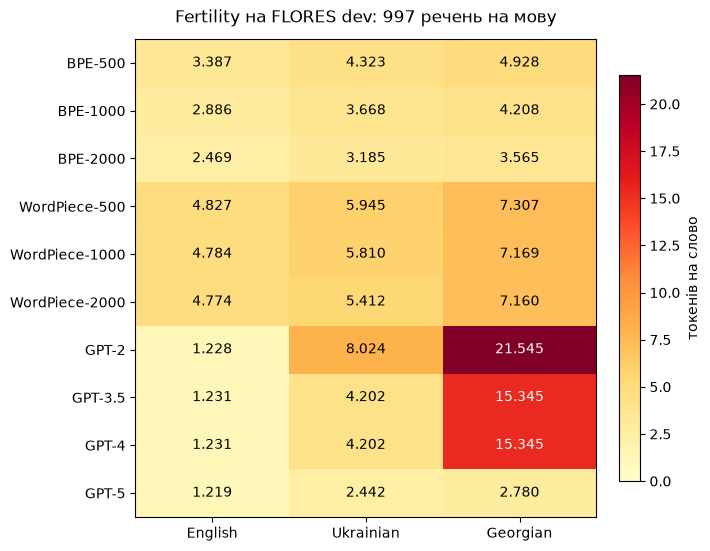

In [21]:
if __name__ == "__main__":
    import matplotlib.pyplot as plt
    import numpy as np

    names = list(results)
    languages = list(flores)
    values = np.array([[results[name][lang] for lang in languages] for name in names])
    fig, ax = plt.subplots(figsize=(7, 5.4), layout="constrained")
    image = ax.imshow(values, cmap="YlOrRd", vmin=0, aspect="auto")
    ax.set_xticks(range(3), ["English", "Ukrainian", "Georgian"])
    ax.set_yticks(range(len(names)), names)
    ax.set_title("Fertility на FLORES dev: 997 речень на мову", pad=12)
    for i in range(len(names)):
        for j in range(3):
            color = "white" if values[i, j] > values.max() * 0.62 else "black"
            ax.text(j, i, f"{values[i, j]:.3f}", ha="center", va="center", color=color)
    fig.colorbar(image, ax=ax, label="токенів на слово", shrink=0.85)
    plt.show()

## 9. Приклади самого розбиття

тут показано самі частини слова: у BPE видно `</w>`, у WordPiece - `##` та `[UNK]`. `decode_single_token_bytes` повертає байти GPT-токена; якщо їх не можна окремо декодувати як UTF-8, показую hex.

межа GPT-токена може проходити всередині багатобайтового символу, тому окремий токен не завжди є читабельним символом. Увесь коректний потік байтів відновлює текст; це не помилка токенізації.

In [22]:
if __name__ == "__main__":
    samples = ["Я навчаю tokenizer на FLORES dataset.", "Київ თბილისი 🌍"]
    for text in samples:
        print(text)
        for name in ("BPE-2000", "WordPiece-2000", "GPT-5"):
            tokens = tokenizers_to_compare[name](text)
            if name == "GPT-5":
                pieces = []
                for token in tokens:
                    raw = gpt_encodings[name].decode_single_token_bytes(token)
                    try:
                        pieces.append(raw.decode("utf-8"))
                    except UnicodeDecodeError:
                        pieces.append("0x" + raw.hex())
            else:
                pieces = tokens
            print(f"{name} ({len(tokens)}): {pieces}")
        for name, tokenize_text in baselines.items():
            ids = tokenize_text(text)
            print(f"{name}: {len(ids)} токенів, {ids.count(1)} невідомих")
        print()

Я навчаю tokenizer на FLORES dataset.
BPE-2000 (19): ['я</w>', 'нав', 'ча', 'ю</w>', 'to', 'k', 'en', 'iz', 'er</w>', 'на</w>', 'fl', 'or', 'es</w>', 'd', 'at', 'as', 'et</w>', '.', '</w>']
WordPiece-2000 (32): ['я', 'н', '##а', '##в', '##ч', '##а', '##ю', 't', '##o', '##k', '##e', '##n', '##i', '##z', '##e', '##r', 'н', '##а', 'f', '##l', '##o', '##r', '##e', '##s', 'd', '##a', '##t', '##a', '##s', '##e', '##t', '[UNK]']
GPT-5 (10): ['Я', ' нав', 'ча', 'ю', ' tokenizer', ' на', ' FLO', 'RES', ' dataset', '.']
Words: 7 токенів, 4 невідомих
Trigrams: 32 токенів, 1 невідомих

Київ თბილისი 🌍
BPE-2000 (8): ['ки', 'ї', 'в</w>', 'თ', 'ბილ', 'ისი</w>', '🌍', '</w>']
WordPiece-2000 (12): ['к', '##и', '##ї', '##в', 'თ', '##ბ', '##ი', '##ლ', '##ი', '##ს', '##ი', '[UNK]']
GPT-5 (7): ['К', 'и', 'їв', ' თბილის', 'ი', '0x20f09f8c', '0x8d']
Words: 3 токенів, 3 невідомих
Trigrams: 12 токенів, 3 невідомих



## 10. Порівняння методів

| Метод | Що стає токеном | Як будується словник | Нове слово | Основний компроміс |
| --- | --- | --- | --- | --- |
| Послівний | Ціле слово, число або знак із `word_tokenize` | Збираю унікальні токени корпусу | Відсутній запис стає `<unk>` | Короткий вхід для відомих слів, але багато словоформ і великий словник |
| Символьні n-грами | Фрагменти фіксованої довжини з перекриттям | Збираю фрагменти корпусу | Відомі частини зберігаються, невідомі стають `<unk>` | Повторне використання частин, але багато фрагментів і проблема коротких слів |
| Наш BPE | Символи та злиті частини з `</w>` | Зливаю найчастіші сусідні пари | Відомі символи можна подати дрібнішими частинами | Більший словник часто скорочує вхід; новий символ може бути поза словником |
| Наш WordPiece | Початкові частини та продовження з `##` | Зливаю пари за нормованим score | Найдовші доступні частини; невдача дає `[UNK]` для всього слова | Можна повторно використовувати підслова, але greedy й покриття обмежують розбиття |
| GPT через tiktoken | Фрагменти на основі байтів і вивчених злиттів | Використовую готовий encoding | Звичайний текст подається байтами без словесного `[UNK]` | Зберігає текст, але довжина залежить від мови й конкретного encoding |

### BPE і WordPiece: дві окремі відмінності

1. **Навчання:** BPE вибирає найбільшу частоту пари, наша схема WordPiece - найбільше `freq(a,b)/(freq(a)×freq(b))`. Обидва методи створюють підслова, але можуть заповнювати словник різними фрагментами.
2. **Застосування:** BPE повторює правила злиття в їхньому порядку. WordPiece шукає найдовші фрагменти у фінальному словнику й позначає продовження через `##`.

Розмір словника сам по собі не говорить, скільки тексту покрито корисними великими частинами. Для нашого WordPiece додаткові записи часто охоплюють рідкісні фрагменти, а частка `[UNK]` у досліді не змінюється. Тому fertility зменшується слабше. Це пояснення результатів цієї реалізації та корпусу; з нього не випливає, що будь-який WordPiece завжди гірше за BPE.

### Що перевіряти разом із fertility

- **Покриття:** скільки вхідних одиниць стало невідомими й яка інформація при цьому втратилася.
- **Відновлення тексту:** чи збереглися регістр, пробіли, пунктуація. Наш `lower()` уже робить точне відновлення початкового тексту неможливим.
- **Довжина на нових даних:** навчальна fertility може бути кращою за результат на окремому тестовому корпусі.
- **Швидкість і пам’ять:** словник потребує місця; збільшення `V` збільшує embedding-таблицю `V×d`, а коротші послідовності зменшують кількість позицій.
- **Складні приклади:** інша мова, нові імена, числа, адреси, emoji та змішаний текст можуть поводитися інакше, ніж середнє речення корпусу.

### Що саме порівняно з GPT

У цій роботі порівнюються готові encodings, а не відповіді мовних моделей. GPT-3.5 і GPT-4 мають однакові числа через спільний `cl100k_base`. Варіант GPT-5 з `o200k_base` дав коротші послідовності для всіх трьох мов у нашій таблиці. Це свідчить про краще стиснення цих текстів токенізатором, але не вимірює знання, точність або здатність моделі міркувати.


## Висновок

Я реалізував усі функції з шаблону та перевірив їх тестами. Словник слів має 21352
елементи, словник триграм - 15649. На навчальному корпусі в них немає невідомих токенів,
але в нових змішаних прикладах вони вже з’являються.

Для BPE збільшення словника з 500 до 2000 скоротило fertility: англійська
3.387 → 2.469, українська 4.323 → 3.185, грузинська 4.928 → 3.565.
У WordPiece скорочення слабше. Його [UNK] замінив 13.22%, 18.24% і 19.01% вхідних
токенів word_tokenize відповідно. Серед них є числа та пунктуація, бо навчання за
умовою брало тільки слова. Через це коротша послідовність не завжди краща.

GPT-2 добре стискає англійський текст (1.228), але грузинський має fertility 21.545.
GPT-3.5 і GPT-4 дали однакові числа, бо використовують cl100k_base.
Найнижчі значення серед десяти порівняних варіантів у цьому досліді має GPT-5:
1.219 для англійської, 2.442 для української, 2.780 для грузинської.

Більший словник потребує більше кроків навчання. Токени не зобов’язані розподілятися
порівну між мовами: однакова кількість речень не означає однакові частоти фрагментів.
Зниження fertility не гарантоване для кожного нового тексту.

Це порівняння на невеликому FLORES dev, де власні моделі також навчалися.
Наші токенізатори знижують регістр, а GPT зберігає його. Тому результати не доводять
загальну перевагу алгоритму. Для вибору токенізатора потрібні також окремий тестовий
корпус, частка невідомих слів, збереження тексту, швидкість і поведінка на різних мовах.
